# Preprocess Roeske et al (2020)

In [1]:
from scipy.io import loadmat
import os
from pathlib import Path
import numpy as np
import pandas as pd

import sys
sys.path.append('../')
from src.data import save_units

# Load data location from .env file
from dotenv import load_dotenv
load_dotenv()
if not os.getenv("RT_DIR"):
    raise Exception("RT_DIR environment variable not set")
DATA_DIR = Path(os.getenv("RT_DIR"))

ROOT_DIR = Path('.').resolve().parent
DATASET_ID = 'rt' # Roeske et al. (2020)
OUTPUT_DIR = ROOT_DIR / 'data'

## Extract units

Note that there are only syllable IOIs (`syll_ioi`) in this case, since we only have inter-syllable intervals. We reinterpret np.nan entries as chunk boundaries, and restart time every time we cross a boundary. We store data in the same format as before.

In [2]:
data = loadmat(DATA_DIR / "zhb728dc4z-1" / "IntervalData_ZebraFinch_corpus.mat")
intervals = data['ZebraFinch_intervals_ms'].squeeze()

In [3]:
units = []
start = 0
chunk_idx = 1
for interval in intervals:
    if np.isnan(interval):
        start = 0
        chunk_idx += 1
    else:
        units.append(dict(
            start = start / 1000,
            duration = interval / 1000,
            chunk_idx = chunk_idx
        ))
        start += interval

columns=['start', 'duration', 'label', 'chunk_idx', 'bird_id']
units = pd.DataFrame(units, columns=columns)

In [4]:
from src.rhythm_types import drop_short_chunks

# A chunk needs at least 2 intervals to derive any dyad
# from it later; chunk_idx alone already uniquely identifies a chunk here
# (it's a running count over the whole stream, not reset per bird -- bird
# identity isn't known yet at this point).
n_before = units['chunk_idx'].nunique()
units = drop_short_chunks(units, by=['chunk_idx'])
n_after = units['chunk_idx'].nunique()
print(f"dropped {n_before - n_after} of {n_before} chunks with fewer than 2 intervals")

dropped 0 of 30549 chunks with fewer than 2 intervals


## Augment predicted bird ids and labels

In [5]:
from src.data import load_units
from src.pipeline.predict_bird_ids import predict_bird_ids
from src.viz.changepoints import plot_changepoints

from src.pipeline.fit_hmms import get_output_dir
from src.hmm import load_fit
from src.metrics.permutation import shuffle_labels_within_chunk

Importing the dtw module. When using in academic works please cite:
  T. Giorgino. Computing and Visualizing Dynamic Time Warping Alignments in R: The dtw Package.
  J. Stat. Soft., doi:10.18637/jss.v031.i07.



### Bird ids

In [6]:
def subsample_chunks(units: pd.DataFrame, max_chunks: int, bird_id_col: str = "bird_id", seed: int = 0) -> pd.DataFrame:
    """Randomly keep at most max_chunks chunks per bird_id_col group."""
    rng = np.random.default_rng(seed)
    keep = []
    for _, group in units.groupby(bird_id_col):
        chunk_ids = group["chunk_idx"].unique()
        if len(chunk_ids) > max_chunks:
            chunk_ids = rng.choice(chunk_ids, size=max_chunks, replace=False)
        keep.append(chunk_ids)
    return units[units["chunk_idx"].isin(np.concatenate(keep))].reset_index(drop=True)

In [7]:
# Bird id predictions
result = predict_bird_ids(
    units, 
    n_individuals=93, # as reported by Roeske et al. (2020)
    half_window=75, 
    min_gap=75, 
    id_prefix=f'{DATASET_ID}-pred-'
)
units['bird_id_pred'] = result['bird_id_pred']

# Sample 50 random chunks per bird to reduce dataset size
units = subsample_chunks(
    units, 
    max_chunks=50, 
    bird_id_col="bird_id_pred", 
    seed=1234
)

# Store units
save_units(units, 'syll_ioi', DATASET_ID, OUTPUT_DIR)

### Labels

In [8]:
units = load_units(DATASET_ID, 'syll_ioi', use_milliseconds=False)

# Label predictions
for bird_id, bird_group in units.groupby('bird_id_pred'):
    path = get_output_dir(DATASET_ID, 'syll_ioi') / f"{bird_id}.joblib"
    if path.exists():
        result = load_fit(path)
        # The fit lists the chunks in chunk order, so the units must be too.
        assert bird_group['chunk_idx'].is_monotonic_increasing
        units.loc[bird_group.index, 'label_pred'] = np.concatenate(result['labels'])

# Shuffled baseline for plots (see preprocess-ns), shuffled from 'label_pred'.
# chunk_idx is unique across the whole dataset (see the drop_short_chunks
# cell above), so no bird grouping is needed.
rng = np.random.default_rng(0)
units['label_shuffle'] = shuffle_labels_within_chunk(
    units, rng, by=['chunk_idx'], label_col='label_pred',
)['label_pred']

# Store units
save_units(units, 'syll_ioi', DATASET_ID, OUTPUT_DIR)

## Visualize

In [9]:
from src.data import load_dyads
from src.viz.dyads_plot import DyadsPlotter
import matplotlib.pyplot as plt

In [10]:
dyads = load_dyads('rt', 'syll_ioi', bird_id_col='bird_id_pred')

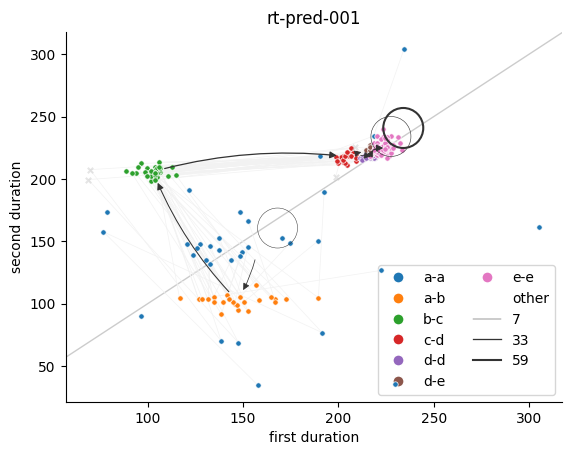

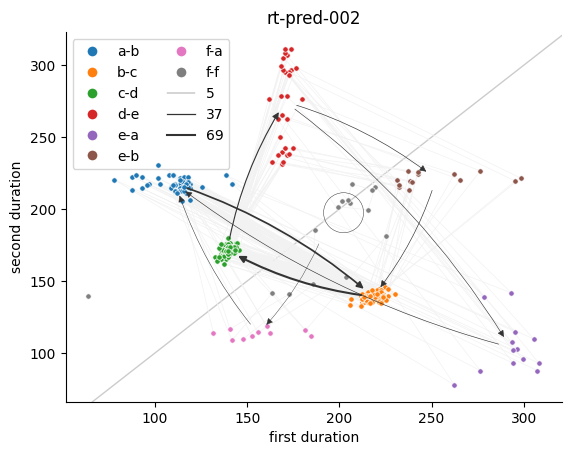

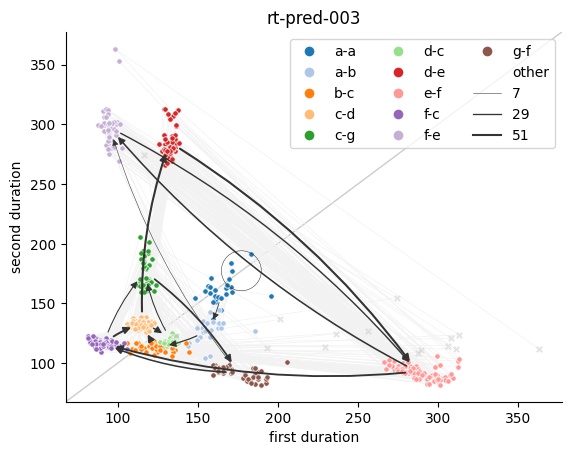

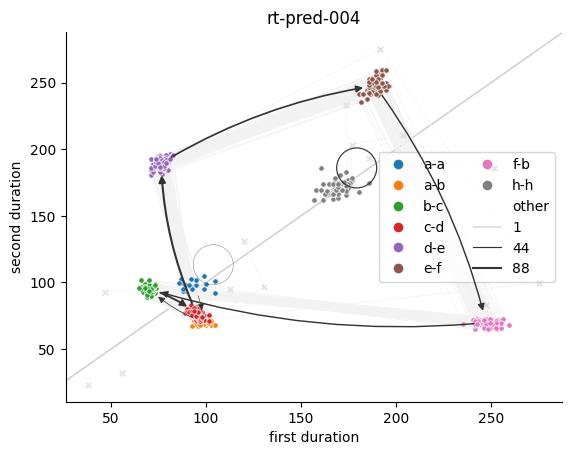

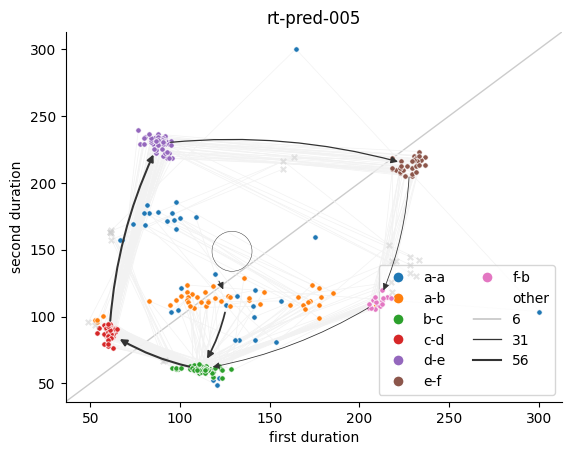

In [11]:
for i in range(1, 6):
    bird = dyads.query(f'bird_id_pred=="rt-pred-00{i}"')

    sp = DyadsPlotter(
        bird[['duration_1', 'duration_2']].to_numpy(), 
        bird['label_pred'], 
        bird['chunk_idx'], 
        max_chunks=200,
        min_label_percentile=2
    )
    sp.scatter()
    sp.transition_network()
    sp.trajectories()
    sp.legend()
    sp.phase_axes()
    plt.title(f"rt-pred-00{i}")
    plt.show()